<a href="https://colab.research.google.com/github/samkenzie/predicting-electrode-transport-properties/blob/main/Dataset_Breakdown.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset Breakdown

The purpose of this file is to explore the dataset of 100,000 computer-generated images of Lithium-ion battery electrode microstructures.

In [9]:
#0. Imports
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import glob

In [4]:
#1. Import data:
!unzip -q /content/64.zip -d /content/images
!unzip -q /content/dispersion.zip -d /content/texts

In [5]:
#2. Loading/storing the effective diffusivity and conductivity values
text_dir = "/content/texts"
eff_diff, eff_cond = [], []

for path in glob.glob("/content/texts/dispersion/*.txt"):
    with open(path) as fh:
        vals = fh.read().split() #Values separated by a new line, thus splits!
        eff_diff.append(float(vals[0]))
        eff_cond.append(float(vals[1]))

print(f"Loaded {len(eff_diff)} files")

Loaded 100000 files


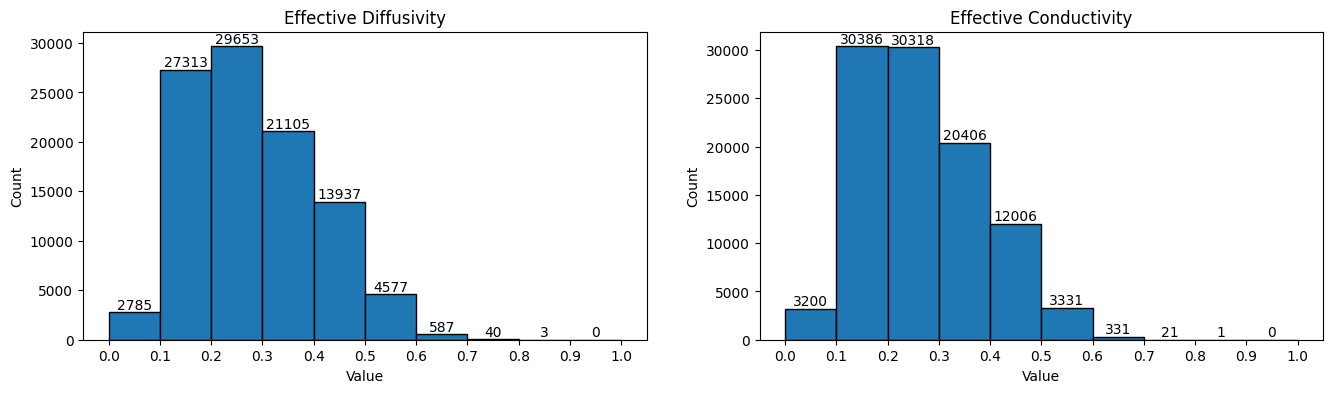

In [15]:
#3. Plotting effective diffusivity and conductivity
bins = np.linspace(0, 1, 11) #11 edges
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

for ax, data, title in zip(axes, [eff_diff, eff_cond], ["Effective Diffusivity", "Effective Conductivity"]):
    ax.hist(data, bins=bins, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
    ax.set_xticks(bins)
    ax.bar_label(ax.containers[0])

There is an obvious bias for effective diffusivity and conductivity values primarily between 0.1 and 0.5.